In [43]:
import requests
import pandas as pd

In [38]:
url = "https://api.open-meteo.com/v1/forecast"
params = {
	"latitude": "tromsø",
	"longitude": -0.1257,
	"hourly": "temperature_2m",
	"timezone": "Europe/Berlin",
	"start_date": "2026-11-02",
	"end_date": "2026-11-09",
}

In [39]:
response = requests.get(url, params=params)
response.raise_for_status()  # Raises an error if the request failed
# data = response.json()

HTTPError: 503 Server Error: Service Unavailable for url: https://api.open-meteo.com/v1/forecast?latitude=troms%C3%B8&longitude=-0.1257&hourly=temperature_2m&timezone=Europe%2FBerlin&start_date=2026-11-02&end_date=2026-11-09

In [26]:
weather = pd.DataFrame({
    "time": data["hourly"]["time"],
    "temperature_2m": data["hourly"]["temperature_2m"],
})

In [25]:
import requests

url = "https://api.met.no/weatherapi/locationforecast/2.0/compact"

params = {
    "lat": 59.91,
    "lon": 10.75,
}

headers = {
    "User-Agent": "jaimes-weather-app/1.0 j.mccutcheon@uit.no"
}

response = requests.get(url, params=params, headers=headers, timeout=10)
response.raise_for_status()

forecast_tromso = response.json()

# cvhange for london
params = {
    "lat": 51.91,
    "lon": 0.75,
}

response = requests.get(url, params=params, headers=headers, timeout=10)
response.raise_for_status()

forecast_london = response.json()


In [8]:
forecast.keys()

dict_keys(['type', 'geometry', 'properties'])

In [13]:
forecast['properties'].keys()

dict_keys(['meta', 'timeseries'])

In [26]:
ts_tromso = forecast_tromso['properties']['timeseries']
ts_london = forecast_london['properties']['timeseries']

In [32]:
ts_tromso[0]

{'time': '2026-11-02T14:00:00Z',
 'data': {'instant': {'details': {'air_pressure_at_sea_level': 1035.6,
    'air_temperature': 9.8,
    'cloud_area_fraction': 1.6,
    'relative_humidity': 57.6,
    'wind_from_direction': 1.0,
    'wind_speed': 2.0}},
  'next_12_hours': {'summary': {'symbol_code': 'clearsky_night'},
   'details': {}},
  'next_1_hours': {'summary': {'symbol_code': 'clearsky_day'},
   'details': {'precipitation_amount': 0.0}},
  'next_6_hours': {'summary': {'symbol_code': 'clearsky_night'},
   'details': {'precipitation_amount': 0.0}}}}

In [40]:


temps_tromso = []
timestamps = []

for t in ts_tromso:
    # print(t['time'], t['data']['instant']['details']['cloud_area_fraction'])
    temps_tromso.append(t['data']['instant']['details']['cloud_area_fraction'])
    timestamps.append(t['time'])


temps_london = []
for t in ts_london:
    # print(t['time'], t['data']['instant']['details']['cloud_area_fraction'])
    temps_london.append(t['data']['instant']['details']['cloud_area_fraction'])


In [ ]:
timestamps = pd.to_datetime(timestamps)
timestamps

df = pd.DataFrame({
    "time": timestamps,
    "tromso": temps_tromso,
    "london": temps_london, 
})



ValueError: All arrays must be of the same length

In [45]:
timestamps


DatetimeIndex(['2026-11-02 14:00:00+00:00', '2026-11-02 15:00:00+00:00',
               '2026-11-02 16:00:00+00:00', '2026-11-02 17:00:00+00:00',
               '2026-11-02 18:00:00+00:00', '2026-11-02 19:00:00+00:00',
               '2026-11-02 20:00:00+00:00', '2026-11-02 21:00:00+00:00',
               '2026-11-02 22:00:00+00:00', '2026-11-02 23:00:00+00:00',
               '2026-11-03 00:00:00+00:00', '2026-11-03 01:00:00+00:00',
               '2026-11-03 02:00:00+00:00', '2026-11-03 03:00:00+00:00',
               '2026-11-03 04:00:00+00:00', '2026-11-03 05:00:00+00:00',
               '2026-11-03 06:00:00+00:00', '2026-11-03 07:00:00+00:00',
               '2026-11-03 08:00:00+00:00', '2026-11-03 09:00:00+00:00',
               '2026-11-03 10:00:00+00:00', '2026-11-03 11:00:00+00:00',
               '2026-11-03 12:00:00+00:00', '2026-11-03 13:00:00+00:00',
               '2026-11-03 14:00:00+00:00', '2026-11-03 15:00:00+00:00',
               '2026-11-03 16:00:00+00:00', '2026-1

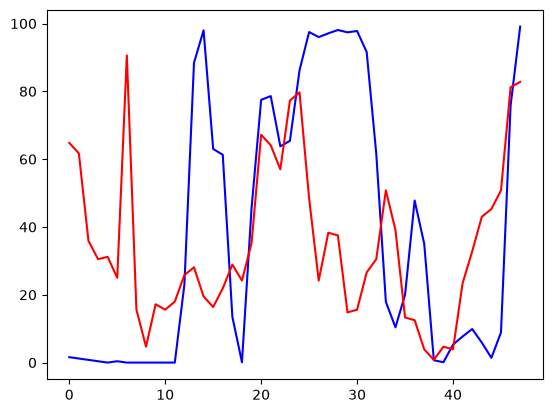

In [35]:
import matplotlib.pyplot as plt

plt.plot(temps_tromso[:48], label='Tromsø', color='blue')
plt.plot(temps_london[:48], label='London', color='red')

In [37]:
temps_tromso = []

for t in ts_tromso:
    print(t['time'], t['data']['next_1_hours']['details']['precipitation_amount'])
    temps_tromso.append(t['data']['instant']['details']['cloud_area_fraction'])


temps_london = []

for t in ts_london:
    print(t['time'], t['data']['instant']['details']['cloud_area_fraction'])
    temps_london.append(t['data']['instant']['details']['cloud_area_fraction'])



2026-11-02T14:00:00Z 0.0
2026-11-02T15:00:00Z 0.0
2026-11-02T16:00:00Z 0.0
2026-11-02T17:00:00Z 0.0
2026-11-02T18:00:00Z 0.0
2026-11-02T19:00:00Z 0.0
2026-11-02T20:00:00Z 0.0
2026-11-02T21:00:00Z 0.0
2026-11-02T22:00:00Z 0.0
2026-11-02T23:00:00Z 0.0
2026-11-03T00:00:00Z 0.0
2026-11-03T01:00:00Z 0.0
2026-11-03T02:00:00Z 0.0
2026-11-03T03:00:00Z 0.0
2026-11-03T04:00:00Z 0.0
2026-11-03T05:00:00Z 0.0
2026-11-03T06:00:00Z 0.0
2026-11-03T07:00:00Z 0.0
2026-11-03T08:00:00Z 0.0
2026-11-03T09:00:00Z 0.0
2026-11-03T10:00:00Z 0.0
2026-11-03T11:00:00Z 0.0
2026-11-03T12:00:00Z 0.0
2026-11-03T13:00:00Z 0.0
2026-11-03T14:00:00Z 0.0
2026-11-03T15:00:00Z 0.0
2026-11-03T16:00:00Z 0.0
2026-11-03T17:00:00Z 0.0
2026-11-03T18:00:00Z 0.0
2026-11-03T19:00:00Z 0.0
2026-11-03T20:00:00Z 0.0
2026-11-03T21:00:00Z 0.0
2026-11-03T22:00:00Z 0.0
2026-11-03T23:00:00Z 0.0
2026-11-04T00:00:00Z 0.0
2026-11-04T01:00:00Z 0.0
2026-11-04T02:00:00Z 0.0
2026-11-04T03:00:00Z 0.0
2026-11-04T04:00:00Z 0.0
2026-11-04T05:00:00Z 0.0


KeyError: 'next_1_hours'